# Sinusoidal Regression

## Imports

In [17]:
import os
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

from scipy.optimize import curve_fit

## Load Data

In [2]:
base_dir = os.path.join(os.getcwd(), '..')
processed_data_dir = os.path.join(base_dir, 'processed_data')

open_meteo_filepath = os.path.join(processed_data_dir, 'open_meteo_processed_data.csv')
open_meteo_df = pd.read_csv(open_meteo_filepath, parse_dates=['datetime'])

## Initial Scatterplot

First, we create a scatterplot of irradiance versus the time of day. We use `alpha=0.03` to make the points transparent. Besause the data has a 30-minute time-resolution, the time of day variable exists in discrete 30-minute bins. For each time of day, more common irradiance values appear darker, as more transparent points overlap.

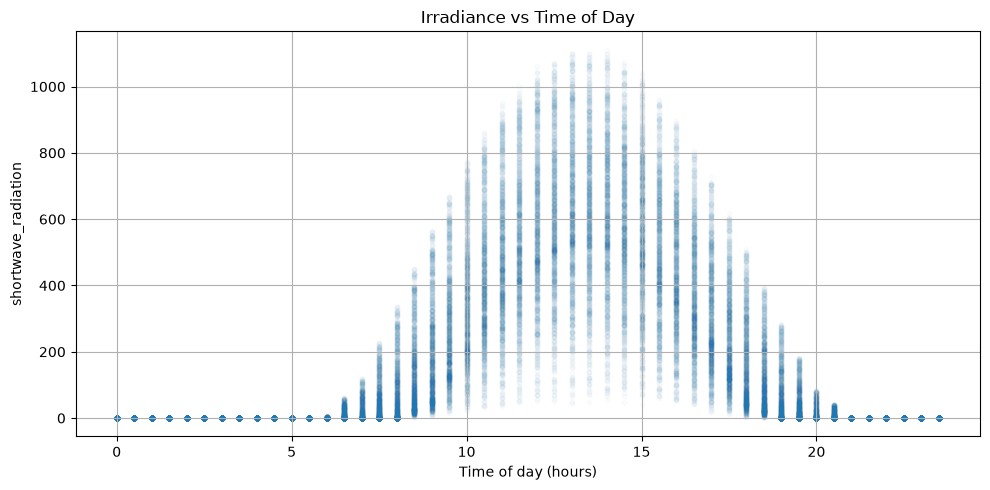

In [15]:
# construct numerical time of day column
open_meteo_df["time_of_day"] = (
    open_meteo_df["datetime"].dt.hour
    + open_meteo_df["datetime"].dt.minute / 60
    + open_meteo_df["datetime"].dt.second / 3600)

plt.figure(figsize=(10, 5))
plt.scatter(open_meteo_df["time_of_day"], open_meteo_df['shortwave_radiation'], alpha=0.02, s=10)
plt.xlabel("Time of day (hours)")
plt.ylabel('shortwave_radiation')
plt.title(f"Irradiance vs Time of Day")
plt.grid(True)
plt.tight_layout()
plt.show()

## Sinusoidal Line-of-best fit
- Source: [(https://www.geeksforgeeks.org/data-analysis/fitting-a-sine-curve-to-data-with-pylab-and-numpy/)]

Useful in any domain where periodic behavior is observed. The general form is:

$y = A \times \sin (Bx + C) + D$
- A = Amplitude
- B = Frequency
- C = Phase Shift
- D = Vertical offset

In [16]:
def sine_function(x, A, B, C, D): return A * np.sin(B * x + C) + D

Fitted parameters: A=311.0294634184605, B=0.33479205140003276, C=-2.8603820559892865, D=239.6188376356625


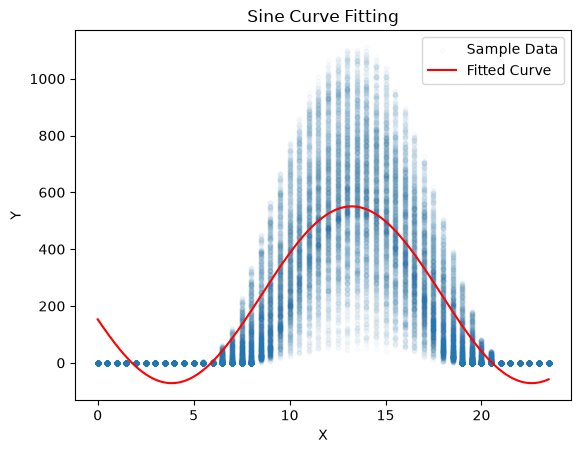

In [ ]:
x = open_meteo_df['time_of_day']
y = open_meteo_df['shortwave_radiation']
initial_guess = [550, 2*np.pi/24, -1.96, 550]

params, covariance = curve_fit(sine_function, x, y, p0=initial_guess)
A_fit, B_fit, C_fit, D_fit = params

print(f"Fitted parameters: A={A_fit}, B={B_fit}, C={C_fit}, D={D_fit}")

# Generate Line-of-Best-Fit
x_fit = np.linspace(x.min(), x.max(), 500)
y_fit = sine_function(x_fit, *params)

# Plot the original data and the fitted curve
plt.scatter(x, y, label='Sample Data', alpha=0.02, s=10)
plt.plot(x_fit, y_fit, label='Fitted Curve', color='red')
plt.xlabel('X')
plt.ylabel('Y')
plt.title('Sine Curve Fitting')
plt.legend()
plt.show()

As we can see, the line-of-best-fit does a decent job of describing all of the data, tending towards the middle of the spread. However, the line of best fit is a bit 'wider' than we would expect, meaning the frequency parameter is a bit off. It seems possible that the zero values are misleading the line of best fit. This makes sense because an oridinary sine function only has two points at the zero crossing per period, but this irradiance data has many zero points. Irradiance is near zero for a long stretch overnight, when a real sine wave only crosses zero twice per cycle. 

Ideas to try: fit a daylight-shaped curve instead: Use a half-sine that is constrained to zero outside sunrise and sunset.

## Daylight Shaped Curve

The daylight half-sine models irradiance as zero overnight, and as a positive arch between sunrise and sunset. It has three parameters: `A` (amplitude), `sunrise`, and `sunset`. The fraction inside `sin` maps the time from sunrise-to-sunset onto angles from 0 to $\pi$.

In [26]:
def daylight_curve(x, A, sunrise, sunset):
    y = np.zeros_like(x, dtype=float)
    daylight = (x >= sunrise) & (x <= sunset)
    y[daylight] = A * np.sin(np.pi * (x[daylight] - sunrise) / (sunset - sunrise))
    return y

Next we fit the parameters with `curve_fit`.

Fitted parameters: A=602.0342026638638, Sunrise=7.613333044274462, Sunset=19.161063987477327


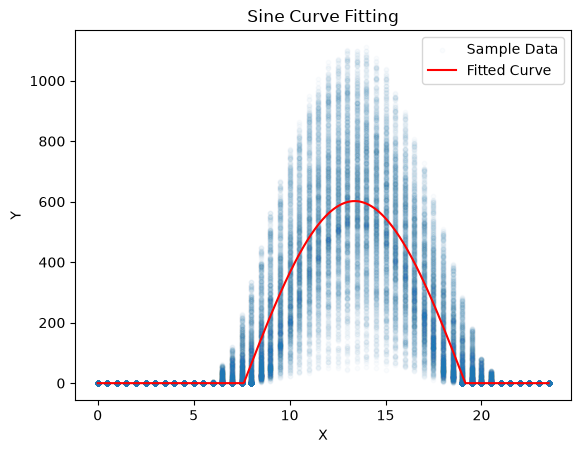

In [31]:
initial_guess = [600, 6.5, 20.5]
params, covariance = curve_fit(daylight_curve, x, y, p0=initial_guess)

A_fit, sunrise_fit, sunset_fit = params
print(f"Fitted parameters: A={A_fit}, Sunrise={sunrise_fit}, Sunset={sunset_fit}")

# Generate Line-of-Best-Fit
x_fit = np.linspace(x.min(), x.max(), 500)
y_fit = daylight_curve(x_fit, *params)

# Plot the original data and the fitted curve
plt.scatter(x, y, label='Sample Data', alpha=0.02, s=10)
plt.plot(x_fit, y_fit, label='Fitted Curve', color='red')
plt.xlabel('X')
plt.ylabel('Y')
plt.title('Sine Curve Fitting')
plt.legend()
plt.show()